# CHLA-Z methods 6: glider retrieval, QC and solar-time windows

**Author:** Eli Holmes (NOAA)<br>
Last updated: November 24, 2026

> **What this notebook is.** One of the *data methods* notebooks for the
> CHLA-Z tables in `datasets/chla_z/data/`, for the glider tables
> (`CHLA_glider_profiles*.parquet`): chlorophyll profiles from 20 IOOS Glider
> DAC deployments, mostly coastal, where OOI has only a few sites. It shows,
> on one Slocum and one Spray deployment, how glider chlorophyll is
> selected, retrieved, quality controlled, reduced to one profile per 3 h
> window, binned and corrected, and checks the result against the released
> table. It is **not** about model training.
>
> **What it is not.** It does not build the tables. The build runs from
> `datasets/chla_z/build.py` (stages `glider-fetch`, `glider`, then `pace`,
> `olci` and their merges with `--platform glider`), which calls the
> functions in `src/chla_z_glider.py` that this notebook calls. The raw
> downloads it reads are on the hub in `notebooks/_temp_data/glider/`.
> Design note and decisions: `claude/notes/chla-z-glider.md`.

The processing follows OOI (methods notebook 2) wherever it can: 3 h windows
of local mean solar time, 10 m bins (A, B] from 0 to 200 m, and the Sauzède
fluorescence:chla correction. The deliberate difference is that a glider
moves, so a window keeps **one** profile instead of averaging all samples.
The table also keeps the fluorometer values and a deep (dark) offset as
columns (section 5). Matchups to PACE and OLCI use the same code and rules as
Argo and OOI (methods notebooks 3 and 4).

In [1]:
import sys

if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chla_z_build as b
import chla_z_glider as g

## 1. Which deployments

`g.candidates()` asks the Glider DAC ERDDAP (gliders.ioos.us) for every
tabledap dataset with `chlorophyll_a` and data since 2024-03-01, then reads
each dataset's metadata: glider type, chlorophyll units, which QC flag it has
(Spray: `chlorophyll_a_qc`; Rutgers Slocums: `chlorophyll_a_qartod_summary_flag`;
many real-time Slocum sets: none). The list is cached; this reads the cache.

In [2]:
cand = g.candidates()
short = g.shortlist(cand)
print(len(cand), "datasets,", cand.deployment.nunique(), "deployments;",
      len(short), "deployments on the shortlist (units, >= 14 days, delayed mode if it exists)")
short.groupby("region").size().rename("deployments").to_frame()

227 datasets, 173 deployments; 147 deployments on the shortlist (units, >= 14 days, delayed mode if it exists)


,deployments
region,
Antarctic Peninsula,2
California Current,58
Mid-Atlantic Bight and slope,65
Off Cape Hatteras / South Atlantic Bight,14
Open Atlantic,2
Southern New England shelf,5
Tropical Atlantic,1


Every shortlisted deployment was screened on one day from the middle of its
record (`g.screen_unit`, statistics in `g.screen_stats`), to catch broken or
uncalibrated fluorometers before fetching months of data. Two failures seen
while exploring set the tests: a profile that is flat at every depth, and a
deep value well above zero (a dark offset that was not removed).

In [3]:
scr = short.merge(g.screen_table(), on="datasetID")
scr.verdict.value_counts().rename("deployments").to_frame()

,deployments
verdict,
ok,114
deep offset > 0.2,21
flat profile,6
no data that day,4
too few samples,1
negatives > 5%,1


From those that passed, 20 deployments were chosen across six regions
(`src/chla_z_glider_selection.json`): delayed mode where it exists, a QC flag
where possible, seasons spread within a region. Two of the first 20 were
replaced after their whole record was plotted (design note), because the
one-day screen cannot see a sensor that drifts later.

Region names are descriptive, not a claim of coverage: no deployment of 14
days or more since 2024-03 is in the Gulf of Mexico, and the one
low-latitude deployment is in the open tropical Atlantic.

In [4]:
sel = cand.set_index("datasetID").loc[g.selection()]
sel[["region", "platform_type", "institution", "minTime", "maxTime", "qc_var"]]

,region,platform_type,institution,minTime,maxTime,qc_var
datasetID,,,,,,
sp020-20250122T1433,California Current,Spray Glider,Scripps Institution of Oceanography,2025-01-22 19:41:45+00:00,2025-05-15 04:07:54+00:00,chlorophyll_a_qc
sp011-20250603T1557,California Current,Spray Glider,Scripps Institution of Oceanography,2025-06-03 17:31:45+00:00,2025-08-05 15:50:00+00:00,chlorophyll_a_qc
sp041-20250923T1716,California Current,Spray Glider,Scripps Institution of Oceanography,2025-09-23 18:37:45+00:00,2026-01-06 15:53:30+00:00,chlorophyll_a_qc
sp203-20250813T1745,California Current,Spray Glider,Scripps Institution of Oceanography,2025-08-13 18:22:30+00:00,2025-10-27 22:29:45+00:00,chlorophyll_a_qc
sp058-20241121T1821,California Current,Spray Glider,Scripps Institution of Oceanography,2024-11-21 19:57:45+00:00,2025-03-10 19:08:45+00:00,chlorophyll_a_qc
ru39-20240429T1522-delayed,Mid-Atlantic Bight and slope,Slocum Glider,Rutgers University,2024-04-29 15:24:01+00:00,2024-05-29 17:09:25+00:00,chlorophyll_a_qartod_summary_flag
sp007-20240425T1202,Mid-Atlantic Bight and slope,Spray Glider,Woods Hole Oceanographic Institution,2024-04-25 13:24:30+00:00,2024-08-26 07:55:45+00:00,chlorophyll_a_qc
ru43-20240904T1539-delayed,Mid-Atlantic Bight and slope,Slocum Glider,Rutgers University,2024-09-04 15:41:38+00:00,2024-10-05 14:50:54+00:00,chlorophyll_a_qartod_summary_flag
maracoos_04-20241203T1457-delayed,Mid-Atlantic Bight and slope,Slocum Glider,Rutgers University,2024-12-03 14:57:41+00:00,2025-01-06 15:14:36+00:00,chlorophyll_a_qartod_summary_flag


## 2. Retrieve one deployment-month

A Rutgers Slocum on the Mid-Atlantic shelf, May 2024. `g.fetch_unit` asks
for the samples with chlorophyll in 0–200 m (`chlorophyll_a!=NaN`, so the
many CTD-only rows of a Slocum are not downloaded), with each sample's own
time (`precise_time`) and, for Slocums, position (`precise_lat/lon`). The
build saves one gzipped CSV per deployment-month; here we read that file.

In [5]:
slocum = "ru39-20240429T1522-delayed"
raw = pd.read_csv(g.RAW_DIR / slocum / "2024-05.csv.gz")
print(len(raw), "samples,", raw.profile_id.nunique(), "profiles")
raw.head()

301930 samples, 3638 profiles


,profile_id,time,latitude,longitude,precise_time,depth,chlorophyll_a,chlorophyll_a_qartod_summary_flag,precise_lat,precise_lon
0,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:26Z,2.411343,1.0950,1,40.129070,-73.655109
1,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:30Z,2.589960,1.1388,1,40.129059,-73.655102
2,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:32Z,2.828115,1.1096,1,40.129054,-73.655099
3,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:34Z,3.125809,1.1169,1,40.129049,-73.655095
4,1714521621,2024-05-01T00:00:21Z,40.128615,-73.654811,2024-04-30T23:57:36Z,3.492964,1.1388,1,40.129044,-73.655092


## 3. Quality control

`g.good_samples` keeps depth in (0, 200] m and, where the dataset has a
chlorophyll flag, flag 1 or 2 (good / not evaluated). A sample's time is its
`precise_time`: on some delayed-mode Slocum sets the profile `time` is about
70 minutes away from the chlorophyll samples it labels.

In [6]:
qc_var = sel.loc[slocum, "qc_var"]
print("flag counts:", raw[qc_var].value_counts().sort_index().to_dict())
good = g.good_samples(raw, qc_var)
print(f"{len(good)} of {len(raw)} samples kept")

flag counts: {1: 301930}


301906 of 301930 samples kept


A Slocum profiles continuously in a sawtooth: each dive and each climb is a
profile. Within one 10 m bin it moves only tens of metres horizontally
(measured on six deployments, 2026-11-23), so one position per profile is
accurate at the scale of a 4 km satellite pixel.

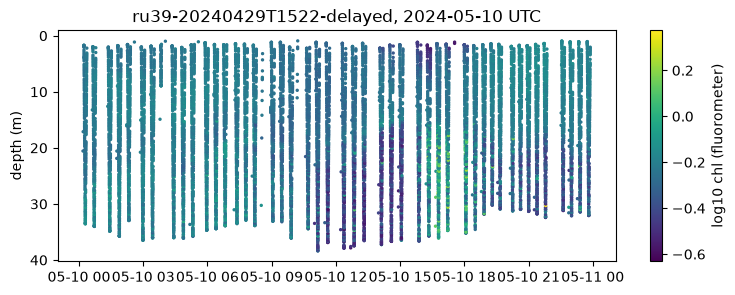

In [7]:
day = good[(good.t >= "2024-05-10") & (good.t < "2024-05-11")]
fig, ax = plt.subplots(figsize=(9, 3))
s = ax.scatter(day.t, day.depth, c=np.log10(day.chlorophyll_a.clip(lower=0.01)), s=2)
ax.invert_yaxis(); ax.set_ylabel("depth (m)")
fig.colorbar(s, label="log10 chl (fluorometer)"); ax.set_title(f"{slocum}, 2024-05-10 UTC");

## 4. One profile per 3 h window of local solar time

Like OOI, rows are 3 h windows of local mean solar time (UTC + lon/15 h),
so each row keeps its time of day (quenching). Unlike OOI, a window keeps
one glider profile rather than averaging all samples: a glider travels
10–80 km a day, and an average would mix positions. `g.window_profiles`
picks the profile with the most filled 10 m bins, ties going to the profile
nearest the window centre. Its time is its mean sample time; lat/lon its mean
sample position. `profile_id` is `<dataset>_<solar date>T<window start hour>`
as for OOI; `glider_profile_id` is the Glider DAC profile.

In [8]:
win = g.window_profiles(good, slocum)
print(len(win), "windows from", good.profile_id.nunique(), "profiles")
win[["profile_id", "time", "lat", "lon", "glider_profile_id", "profiles_in_window",
     "max_depth", "CHLA_0_10", "CHLA_20_30"]].head(8)

231 windows from 3638 profiles


,profile_id,time,lat,lon,glider_profile_id,profiles_in_window,max_depth,CHLA_0_10,CHLA_20_30
0,ru39-20240429T1522-delayed_20240430T18,2024-05-01 00:35:13.594936832+00:00,40.123168,-73.651251,1714523714,9,46.108303,1.213503,1.057689
1,ru39-20240429T1522-delayed_20240430T21,2024-05-01 03:17:00.787878912+00:00,40.103330,-73.634225,1714533426,16,40.760860,1.020053,1.168456
2,ru39-20240429T1522-delayed_20240501T00,2024-05-01 07:09:11.700000+00:00,40.079715,-73.604936,1714547352,14,40.522840,0.892164,1.110434
3,ru39-20240429T1522-delayed_20240501T03,2024-05-01 09:22:10.249999872+00:00,40.060347,-73.585521,1714555331,18,37.764748,0.809570,1.072694
4,ru39-20240429T1522-delayed_20240501T06,2024-05-01 12:11:16.893129728+00:00,40.037576,-73.563985,1714565477,15,41.286938,0.348453,1.577843
5,ru39-20240429T1522-delayed_20240501T09,2024-05-01 14:55:07.885245952+00:00,40.022782,-73.549944,1714575317,15,40.572655,0.197448,1.499922
6,ru39-20240429T1522-delayed_20240501T12,2024-05-01 18:18:25.546874880+00:00,40.007564,-73.529378,1714587511,16,41.455715,0.195275,1.391424
7,ru39-20240429T1522-delayed_20240501T15,2024-05-01 21:23:27.414966016+00:00,39.985232,-73.503548,1714598607,16,40.086643,0.381790,1.118245


The shelf is about 40–80 m deep here, so the deeper bins are empty (NaN). On
the shelf that is real, and a model has to accept it.

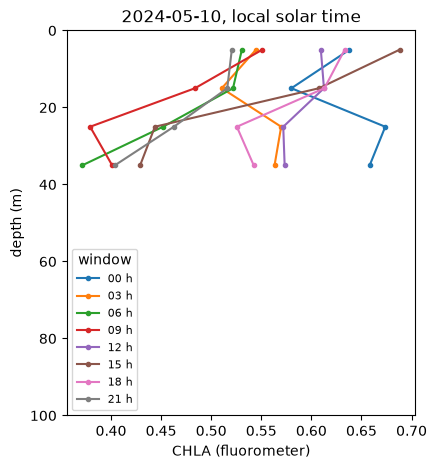

In [9]:
mid = np.arange(5, 200, 10)
d = win[win.profile_id.str.contains("_20240510T")]
fig, ax = plt.subplots(figsize=(4.5, 5))
for _, r in d.iterrows():
    ax.plot(r[b.CHLA_COLS].to_numpy(float), mid, marker=".", label=r.profile_id[-2:] + " h")
ax.set_ylim(100, 0); ax.set_xlabel("CHLA (fluorometer)"); ax.set_ylabel("depth (m)")
ax.legend(title="window", fontsize=8); ax.set_title("2024-05-10, local solar time");

A Spray records only on the way up, one profile every 2–3 hours, so most
windows hold one profile already. Sprays carry no per-sample position
(`precise_lat` is empty), so they use the profile position. Example: off
Cape Hatteras, November 2024.

In [10]:
spray = "sp066-20241106T1639"
sraw = pd.read_csv(g.RAW_DIR / spray / "2024-11.csv.gz")
swin = g.window_profiles(g.good_samples(sraw, sel.loc[spray, "qc_var"]), spray)
print(len(swin), "windows;", swin.profiles_in_window.value_counts().sort_index().to_dict(),
      "(profiles per window: count)")

158 windows; {1: 117, 2: 30, 3: 7, 4: 2, 5: 1, 6: 1} (profiles per window: count)


## 5. Sauzède correction, raw values and the dark offset

**Sauzède.** Glider fluorometers (WET Labs ECO on Slocums, an equivalent on
Sprays) are factory-calibrated, like OOI's. The table divides by the Sauzède
ratio at the profile position, as for OOI: `CHLA_A_B = CHLA_FLUOR_A_B /
chla_ratio`. The ratio differs a lot by region:

In [11]:
prof = pd.read_parquet(b.DATA_DIR / "CHLA_glider_profiles.parquet")
prof.groupby("region").chla_ratio.agg(["min", "median", "max"]).round(2)

,min,median,max
region,,,
Antarctic Peninsula,2.91,2.91,3.35
California Current,0.89,1.66,2.27
Mid-Atlantic Bight and slope,1.20,1.33,1.60
Off Cape Hatteras / South Atlantic Bight,1.19,1.38,1.83
Southern New England shelf,1.37,1.37,1.37
Tropical Atlantic,1.09,1.17,1.19


**Raw values are kept.** `CHLA_FLUOR_A_B` are the fluorometer bin means as
published (after QC, nothing subtracted or divided). The raw ERDDAP samples
are also kept on the hub (`_temp_data/glider/raw/`, `raw_deep/`).

In [12]:
fluor = [c.replace("CHLA_", "CHLA_FLUOR_") for c in b.CHLA_COLS]
back = prof[b.CHLA_COLS].to_numpy() * prof.chla_ratio.fillna(1).to_numpy()[:, None]
print("max |CHLA * chla_ratio - CHLA_FLUOR|:", np.nanmax(np.abs(back - prof[fluor].to_numpy())))

max |CHLA * chla_ratio - CHLA_FLUOR|: 3.552713678800501e-15


**Dark offset (a column, not subtracted).** Below 300 m a fluorometer should
read about 0. Glider fluorometers often do not, and the offset drifts within
a deployment. For every glider profile that reaches 300 m, `g.dark_series`
takes the centred 3-day running median of all QC-passing samples below 300 m
(fetched separately by `g.fetch_deep_unit`); 300 m, not 150 m, because East
Coast Sprays still have real chlorophyll at 150–200 m. Gliders that never
reach 300 m (the shelf Slocums, capex690) get NaN: their deepest water can
hold real chlorophyll, so it is not a dark reference.

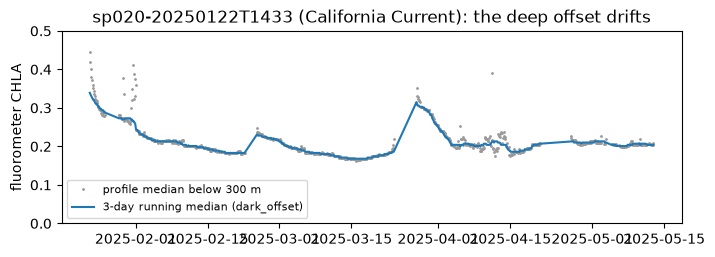

In [13]:
ds = g.dark_series("sp020-20250122T1433")
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(ds.t, ds.dark_profile, ".", ms=2, color="0.6", label="profile median below 300 m")
ax.plot(ds.t, ds.dark_smooth, lw=1.5, label="3-day running median (dark_offset)")
ax.set_ylabel("fluorometer CHLA"); ax.set_ylim(0, 0.5); ax.legend(fontsize=8)
ax.set_title("sp020-20250122T1433 (California Current): the deep offset drifts");

In [14]:
prof.groupby("dataset_id").agg(
    dark_offset_rows=("dark_offset", "count"), dark_offset=("dark_offset", "median"),
    fluor_150_160=("CHLA_FLUOR_150_160", "median"), fluor_190_200=("CHLA_FLUOR_190_200", "median")).round(3)

,dark_offset_rows,dark_offset,fluor_150_160,fluor_190_200
dataset_id,,,,
capex690-20260812T1423-delayed,0,NaN,0.078,0.060
maracoos_04-20241203T1457-delayed,0,NaN,NaN,NaN
ru26d-20250107T1348,512,0.102,0.127,0.113
ru26d-20260130T2026-delayed,439,0.095,0.103,0.099
ru34-20241102T1737-delayed,0,NaN,NaN,NaN
ru34-20250113T1244-delayed,0,NaN,NaN,NaN
ru34-20250311T1220-delayed,0,NaN,NaN,NaN
ru39-20240429T1522-delayed,0,NaN,NaN,NaN
ru43-20240904T1539-delayed,0,NaN,NaN,NaN


Why it is not subtracted: it makes the gliders disagree with PACE and with
Argo (section 8, last cell). A user who wants it removed computes
`(CHLA_FLUOR_A_B - dark_offset) / chla_ratio`.

## 6. Check against the released table

In [15]:
# The month's windows (before the Sauzède division) against the table's raw columns.
m = win.merge(prof, on="profile_id", suffixes=("", "_table"))
m = m[m.time.dt.strftime("%Y-%m") == "2024-05"]
# Windows at the month's edges can differ: the table pools all months first.
diff = np.zeros(len(m), bool)
for c, f in zip(b.CHLA_COLS, fluor):
    diff |= ~np.isclose(m[c], m[f], equal_nan=True)
print(f"{len(m)} windows compared, {diff.sum()} differ")
assert diff.sum() <= 2

231 windows compared, 0 differ


## 7. The whole glider table

One panel per deployment: the chosen profile of each window, over the
deployment, after QC and the Sauzède correction.

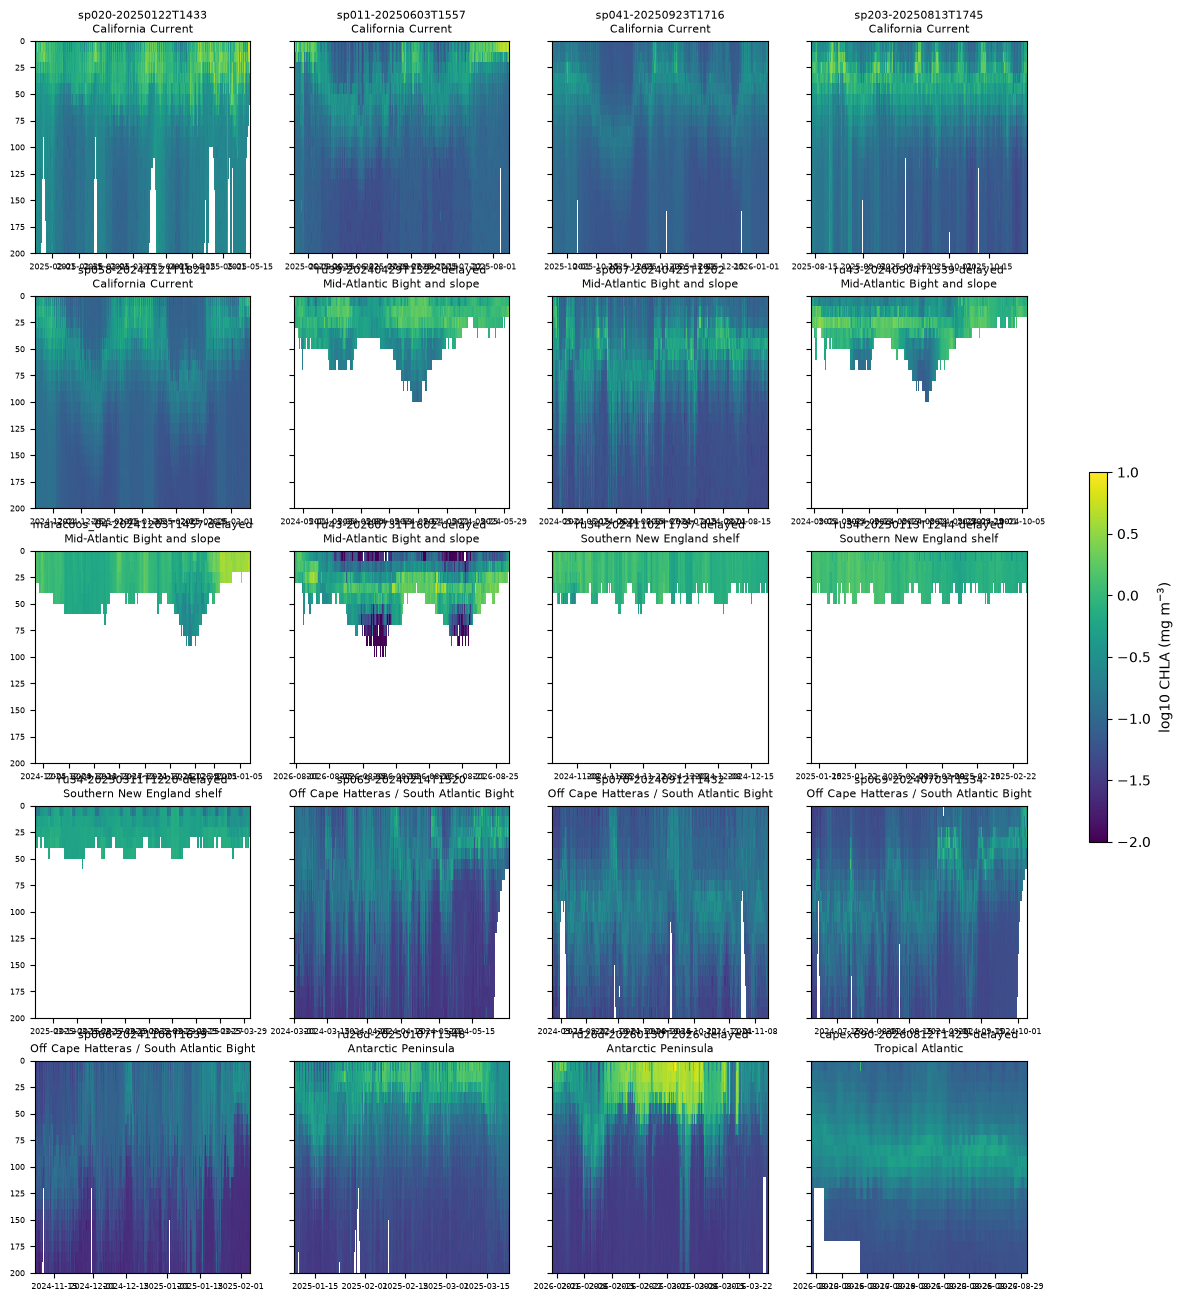

In [16]:
ids = g.selection()
fig, axs = plt.subplots(5, 4, figsize=(16, 16), sharey=True)
for ax, d_ in zip(axs.flat, ids):
    w = prof[prof.dataset_id == d_].sort_values("time")
    im = ax.pcolormesh(w.time, mid, np.log10(np.clip(w[b.CHLA_COLS].to_numpy(float), 0.01, None)).T,
                       vmin=-2, vmax=1, shading="nearest")
    ax.set_title(f"{d_}\n{w.region.iloc[0]}", fontsize=8); ax.tick_params(labelsize=6)
axs[0, 0].set_ylim(200, 0)
fig.colorbar(im, ax=axs, shrink=0.3, label="log10 CHLA (mg m$^{-3}$)");

In [17]:
summary = prof.groupby("region").agg(
    deployments=("dataset_id", "nunique"), rows=("profile_id", "size"),
    median_shore_km=("shore_km", "median"), median_max_depth_m=("max_depth", "median"))
summary.round(1)

,deployments,rows,median_shore_km,median_max_depth_m
region,,,,
Antarctic Peninsula,2,955,32.1,199.4
California Current,5,3688,70.5,197.4
Mid-Atlantic Bight and slope,5,1486,93.5,60.4
Off Cape Hatteras / South Atlantic Bight,4,1817,172.6,197.4
Southern New England shelf,3,844,26.8,34.2
Tropical Atlantic,1,133,635.2,192.5


## 8. Matchups

The glider tables are matched exactly as Argo and OOI (methods notebooks 3
and 4): PACE V3.2 daily 4 km Rrs, chlor_a, Kd_490, a profile matching a
granule when its time is within 24 h after the granule's
`time_coverage_start` (standard before NRT, nearest cell); OLCI S3A/S3B daily
4 km Rrs from the file of the profile's UTC day. The choice of time rule is
discussed in fish-pace/fish-pace-datasets#10, which has a comparison of both
rules on these glider profiles.

In [18]:
rrs_cols = [f"pace_Rrs_{x}" for x in b.RRS_LABELS]
pace = pd.read_parquet(b.DATA_DIR / "CHLA_glider_profiles_plus_PACE.parquet")
olci = pd.read_parquet(b.DATA_DIR / "CHLA_glider_profiles_plus_OLCI.parquet")
v = pace[pace[rrs_cols].notna().any(axis=1)]
tab = prof.groupby("region").size().rename("profiles").to_frame()
tab["PACE granule"] = pace.groupby("region").size()
tab["PACE valid Rrs"] = v.groupby("region").size()
tab["OLCI valid Rrs_443"] = olci[np.isfinite(olci.olci_Rrs_443)].groupby("region").size()
tab["OLCI and PACE"] = olci[np.isfinite(olci.olci_Rrs_443) & olci.pace_Rrs_valid].groupby("region").size()
tab.loc["total"] = tab.sum()
tab.fillna(0).astype(int)

,profiles,PACE granule,PACE valid Rrs,OLCI valid Rrs_443,OLCI and PACE
region,,,,,
Antarctic Peninsula,955,914,88,72,28
California Current,3688,3546,1176,1197,757
Mid-Atlantic Bight and slope,1486,1334,402,461,274
Off Cape Hatteras / South Atlantic Bight,1817,1643,279,546,187
Southern New England shelf,844,820,339,362,265
Tropical Atlantic,133,133,5,42,0
total,8923,8390,2289,2680,1511


Matchups by local solar hour (the quenching question needs both day and night):

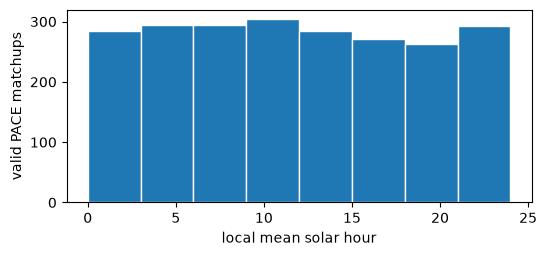

In [19]:
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.hist(v.solar_hour, bins=np.arange(0, 25, 3), edgecolor="w")
ax.set_xlabel("local mean solar hour"); ax.set_ylabel("valid PACE matchups");

Distance to shore of the valid matchups. The table keeps `shore_km` (Natural
Earth 10 m coastline) so near-shore pixels can be filtered; PACE L3 already
masks land and many adjacency pixels.

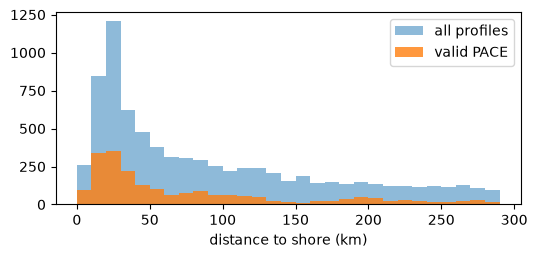

In [20]:
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.hist(prof.shore_km, bins=np.arange(0, 300, 10), alpha=0.5, label="all profiles")
ax.hist(v.shore_km, bins=np.arange(0, 300, 10), alpha=0.8, label="valid PACE")
ax.set_xlabel("distance to shore (km)"); ax.legend();

Satellite chlorophyll against the glider's shallowest bin (Sauzède-corrected),
coloured by solar hour. This is only a sanity check, not a validation: the
glider bin is 0–10 m, the PACE value a daily 4 km composite.

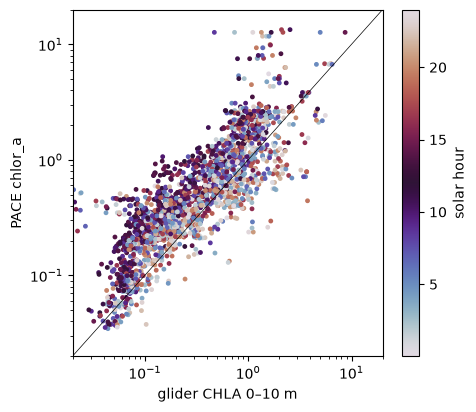

In [21]:
fig, ax = plt.subplots(figsize=(5, 4.5))
s = ax.scatter(v.CHLA_0_10, v.pace_chlor_a, c=v.solar_hour, cmap="twilight", s=6)
lim = [0.02, 20]
ax.plot(lim, lim, "k", lw=0.5); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("glider CHLA 0–10 m"); ax.set_ylabel("PACE chlor_a")
fig.colorbar(s, label="solar hour");

The flat rows of very high PACE chlor_a (about 8–27 mg m⁻³) are near-shore
atmospheric-correction failures: mostly near the coast (California Current
Sprays), with Rrs(442) near zero or negative, and many times the glider value. They show why `shore_km` is kept; a coastal
training set needs a near-shore or Rrs-quality filter.

In [22]:
hi = v[v.pace_chlor_a > 8]
print(len(hi), "matchups with PACE chlor_a > 8; distance to shore (km):",
      hi.shore_km.round(1).describe()[["min", "50%", "max"]].to_dict())
hi[["dataset_id", "time", "shore_km", "CHLA_0_10", "pace_chlor_a", "pace_Rrs_442"]].head()

29 matchups with PACE chlor_a > 8; distance to shore (km): {'min': 3.2, '50%': 11.9, 'max': 43.2}


,dataset_id,time,shore_km,CHLA_0_10,pace_chlor_a,pace_Rrs_442
3703,ru34-20250113T1244-delayed,2025-01-23 00:32:12.770000+00:00,33.263589,1.628349,9.953812,-0.000570
3836,sp020-20250122T1433,2025-01-27 01:05:03+00:00,10.386450,2.102163,13.396170,0.000254
3839,sp020-20250122T1433,2025-01-27 03:21:47+00:00,9.214395,2.353949,26.884167,-0.000106
3845,sp020-20250122T1433,2025-01-27 06:15:17+00:00,7.784317,3.754828,26.884167,-0.000106
3848,sp020-20250122T1433,2025-01-27 09:14:42+00:00,6.472385,1.573243,26.884167,-0.000106


PACE chlor_a / glider CHLA_0_10 by local solar hour. Fluorescence quenching
in daylight lowers the glider value, so the ratio peaks around noon.

In [23]:
vv = v[(v.CHLA_0_10 > 0) & v.pace_chlor_a.notna()]
r = np.log10(vv.pace_chlor_a / vv.CHLA_0_10)
hb = pd.cut(vv.solar_hour, [0, 6, 9, 15, 18, 24], right=False)
(10 ** r.groupby(hb, observed=True).median()).round(2).rename("median PACE/glider").to_frame().assign(
    n=r.groupby(hb, observed=True).size())

,median PACE/glider,n
solar_hour,,
"[0, 6)",1.39,577
"[6, 9)",1.65,295
"[9, 15)",2.21,587
"[15, 18)",1.60,271
"[18, 24)",1.35,553


The same ratio at night (solar hour outside 6–18 h, little quenching), with
and without subtracting `dark_offset`, for the gliders that have one. For
reference, Argo's night ratio in the released table is about 1.25.

In [24]:
night = vv[~vv.solar_hour.between(6, 18) & vv.dark_offset.notna()]
dc = (night.CHLA_FLUOR_0_10 - night.dark_offset) / night.chla_ratio
ok = dc > 0
print(f"n = {len(night)}; night median PACE/glider, Sauzède only (CHLA_0_10): "
      f"{10 ** np.median(np.log10(night.pace_chlor_a / night.CHLA_0_10)):.2f}")
print(f"with dark_offset subtracted: "
      f"{10 ** np.median(np.log10(night.pace_chlor_a[ok] / dc[ok])):.2f} (n = {ok.sum()})")

n = 819; night median PACE/glider, Sauzède only (CHLA_0_10): 1.19
with dark_offset subtracted: 1.99 (n = 818)
